from transformers import pipeline, set_seed
generator = pipeline('text-generation', model='lucone83/deep-metal', device=-1)  # to use GPU, set device=<CUDA_device_ordinal>
set_seed(42)
generator(
        "End of passion play",
        num_return_sequences=1,
        max_length=256,
        min_length=128,
        top_p=0.97,
        top_k=0,
        temperature=0.90,
        repetition_penalty=1.2
    )

In [1]:
from transformers import GPT2Tokenizer, GPT2Model

tokenizer = GPT2Tokenizer.from_pretrained('lucone83/deep-metal')
model = GPT2Model.from_pretrained('lucone83/deep-metal')
text = "Replace me by any text you'd like."
encoded_input = tokenizer(text, return_tensors='pt')
output_features = model(**encoded_input)
output_features.keys()
output_features['last_hidden_state'].mean(dim=1)

C:\Users\LOZAY\OneDrive\Documents\pao\metal-mining\.pao\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 148/148 [00:00<00:00, 291.58it/s]
[transformers] GPT2Model LOAD REPORT from: lucone83/deep-metal
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tensor([[-8.9916e-02,  1.9758e-01, -7.3428e-01,  2.6750e-01, -3.3234e-02,
         -1.8196e-02,  1.6688e+00, -1.7393e-01,  1.2103e-01, -1.4592e-01,
          2.4754e-01, -5.7365e-01, -3.6073e-01,  2.0622e-01, -7.5247e-02,
         -4.7796e-02, -5.3904e-02, -6.7513e-01,  5.7717e-01,  4.2553e-01,
          1.0988e-01, -1.9687e-01, -3.4351e-01, -3.7299e-02,  1.6653e-01,
          1.8337e-01, -4.3482e-01, -1.2454e-01,  2.7645e-01,  2.9122e-02,
         -1.9094e-01, -1.1015e-01, -1.0371e-01, -4.1685e-01,  2.3675e-02,
         -2.1251e-01, -4.7435e+01,  2.6280e-01,  2.3993e-01,  4.0749e-01,
         -4.0697e-01,  1.2108e-03, -6.4679e-02, -3.0951e-01,  3.5940e-02,
         -6.0766e-02,  7.4012e-02, -2.1904e-01, -2.5360e-01,  8.7283e-01,
         -1.7546e-01,  2.4276e-01, -5.8282e-02,  2.4828e-01, -1.3196e-01,
          3.0283e-01,  3.0716e-01,  2.2800e-01,  3.7544e-01, -8.2216e-04,
         -1.0950e-01,  3.3322e-01, -6.7777e-02,  1.4912e-01, -1.1272e+00,
          3.3457e-01,  1.2283e-01, -4.

In [2]:
import pandas as pd
album_Karelian = pd.read_csv("album_Karelian.csv")

In [18]:
embedding_album_doom = {}
for i in range(len(album_Karelian)) : 
    encoded_input = tokenizer(album_Karelian.iloc[i]["paroles"], return_tensors='pt')
    output_features = model(**encoded_input)
    output_features.keys()
    embedding = output_features['last_hidden_state'].mean(dim=1)
    embedding_album_doom[album_Karelian.iloc[i]["titre"]] = embedding

In [15]:
album_Lucifer = pd.read_csv("album_Lucifer_heritage.csv")
embedding_album_speed = {}
for i in range(len(album_Lucifer)) : 
    encoded_input = tokenizer(album_Lucifer.iloc[i]["paroles"], return_tensors='pt')
    output_features = model(**encoded_input)
    output_features.keys()
    embedding = output_features['last_hidden_state'].mean(dim=1)
    embedding_album_speed[album_Lucifer.iloc[i]["titre"]] = embedding

In [3]:
songs = pd.read_csv("songs_doom&speed.csv")
songs = songs.dropna(subset=["paroles"]).copy()
songs = songs[songs["paroles"].str.strip() != ""].reset_index(drop=True)

In [4]:
import numpy as np
import torch
def embed_texte(texte):
    inputs = tokenizer(texte, return_tensors="pt", truncation=True, max_length=512)
    with torch.no_grad():
        output = model(**inputs)
    return output.last_hidden_state.mean(dim=1).squeeze(0).numpy()

In [5]:
from tqdm.auto import tqdm   # version adaptée aux notebooks
#vecteur calculé pour chansons doom et speed
#vecteurs = np.vstack([embed_texte(t) for t in tqdm(songs["paroles"], desc="Embeddings")])

emb = pd.DataFrame(
    vecteurs,
    index=pd.MultiIndex.from_frame(songs[["genre", "titre"]]),
    columns=[f"dim_{i}" for i in range(vecteurs.shape[1])],
)

In [7]:
#emb.to_csv("embeddings_par_genre.csv")

emb = pd.read_csv("embeddings_par_genre.csv", index_col=["genre", "titre"])

comment retrouver ensuite
emb.loc[("doom", "A National Acrobat")]      # le vecteur d'une chanson
emb.loc["doom"]                        # toutes les chansons doom
emb.loc["doom"].to_numpy()             # en tableau NumPy, prêt pour PCA / t-SNE

## Classification

eviter les doublons une même chanson peut être classifiée doom et speed 

In [8]:
cle = songs["titre"].str.strip().str.lower()

nb_genres = songs.groupby(cle)["genre"].nunique()
print((nb_genres > 1).sum(), "chansons multi-genres sur", len(nb_genres))

23 chansons multi-genres sur 2174


In [10]:
premiere = ~cle.duplicated()
uniques = songs[premiere].copy()
X = emb[premiere.to_numpy()]

genres_par_chanson = songs.groupby(cle)["genre"].apply(lambda s: sorted(set(s)))
uniques["genres"] = cle[premiere].map(genres_par_chanson).to_numpy()

In [13]:
sans_ambiguite = uniques["genres"].str.len() == 1
X_clean = X[sans_ambiguite.to_numpy()].to_numpy()
y_clean = uniques.loc[sans_ambiguite, "genres"].str[0].to_numpy()
groupes = uniques.loc[sans_ambiguite, "artiste"].str[0].to_numpy()

In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y_clean, test_size=0.2, stratify=y_clean
)

In [34]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

base = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

clf = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, class_weight="balanced", C=0.1),
)
clf.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['doom','speed']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,768
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [35]:
#comparaison baseline et classifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report

modeles = {
    "baseline (majoritaire)": base,
    "régression logistique": clf,
}

for nom, m in modeles.items():
    y_p = m.predict(X_test)
    print(f"{nom:25s} acc={accuracy_score(y_test, y_p):.3f}  "
          f"bal_acc={balanced_accuracy_score(y_test, y_p):.3f}  "
          f"f1_macro={f1_score(y_test, y_p, average='macro'):.3f}")

baseline (majoritaire)    acc=0.756  bal_acc=0.500  f1_macro=0.431
régression logistique     acc=0.884  bal_acc=0.868  f1_macro=0.850


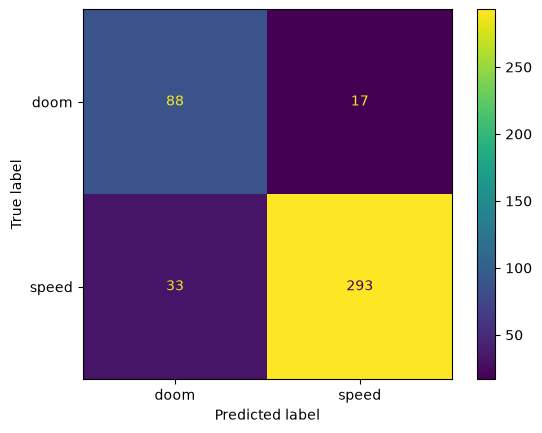

In [36]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

stratify ne tient aucun compte des groupes. Des chansons d’un même album (ou d’un même groupe) se retrouvent dans le train et dans le test. Le modèle peut alors reconnaître le vocabulaire, les thèmes ou le style d’un groupe plutôt que le genre, et le score est trop optimiste.